# ARCADE → CADICA: Cross-Dataset Generalisation (A) + Validated Explainability (B)

**Thesis objectives covered:** Objective 3 (cross-dataset test) and Objective 2 (explainability), using your best existing model (DeepLabV3+ ResNet101 trained on ARCADE).

## What this notebook does
**Part A – cross-dataset test.** Takes the ARCADE-trained model *unchanged* and tests it on CADICA (a different hospital / acquisition, box labels only). The same lesion-level protocol is applied to ARCADE-test and CADICA, so the **drop is an apples-to-apples number**. It then tests two cheap, label-free fixes: per-image intensity stretch and **AdaBN** (re-estimate BatchNorm statistics on the unlabeled target images).

**Part B – explainability that is measured, not just drawn.**
1. Seg-Grad-CAM heat-maps per predicted lesion.
2. Quantitative checks: localisation (pointing game, energy lift), **faithfulness** (deletion test vs random), **sanity** (weight-randomisation test).
3. **Use the explanation:** analyse *why* false positives happen, and train a small false-positive rejector on ARCADE-val features (with and without CAM features). Test whether it raises precision on ARCADE-test and CADICA.

## Before you run
Nothing to upload. The notebook **downloads CADICA by itself** (Mendeley Data public API, straight to Colab's local disk; nothing is written to Drive) and ARCADE via kagglehub.
* If you already have the trained checkpoint on Drive (`MyDrive/arcade_stenosis_runs/dl3_resnet101/best.pt`) it is *read* (not written). Otherwise the model is trained here (**FAST_MODE**: 45 epochs, ~20-25 min on a T4).
* Runtime: **GPU (T4)**. Total ≈ 45-60 min with `FAST_MODE=True`.
* If the automatic CADICA download fails, the error message tells you exactly what to do (paste a direct link into `CADICA_DIRECT_URL`).

## Screenshots to send me
Cells print banners **`=== SS-1 ===` … `=== SS-13 ===`**. Send those outputs (tables and figures) in order.

## Honest framing
CADICA has *bounding boxes only* and covers lesions of all severities, while ARCADE labels are polygon bands. So everything here is **box-level** evaluation. We report three matching rules (IoU≥0.5, IoU≥0.1, centre-hit) and never compare the numbers with StenUNet's 0.535 (different protocol). Confidence intervals come from a **patient-level cluster bootstrap**.

In [1]:
!pip install -q segmentation-models-pytorch pycocotools scikit-image kagglehub albumentations scikit-learn scipy
print("Installs complete.")

Installs complete.


In [2]:
import os, json, zipfile, re, math, random, shutil, copy, warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
import albumentations as A
import segmentation_models_pytorch as smp

from skimage.measure import regionprops
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_CUDA = DEVICE.type == "cuda"
print("Torch", torch.__version__, "| smp", smp.__version__, "| device", DEVICE,
      "|", torch.cuda.get_device_name(0) if USE_CUDA else "NO GPU (will be very slow)")

Torch 2.14.1+cu130 | smp 0.6.0 | device cuda | Tesla T4


In [3]:
# ============================================================
# CONFIG  (the only cell you normally need to edit)
# ============================================================
IMG_SIZE = 512
STENOSIS_CATEGORY_ID = 26

FAST_MODE = True              # smaller/faster settings (recommended on a free T4); False = fuller run

OUT_DIR    = Path("/content/outputs"); OUT_DIR.mkdir(parents=True, exist_ok=True)   # results are saved here (local disk)
CKPT_PATH  = Path("/content/work/dl3_best.pt")                                      # training saves here (local disk)
TRY_DRIVE  = True             # only to READ an existing checkpoint; NOTHING is ever written to Drive
DRIVE_CKPT = Path("/content/drive/MyDrive/arcade_stenosis_runs/dl3_resnet101/best.pt")
FORCE_RETRAIN = False

CADICA_SRC = None             # None = download automatically; or a path to a .zip / extracted folder
CADICA_DIRECT_URL = None      # optional: paste any direct zip URL here if the automatic download fails
MAX_FRAMES_PER_VIDEO = 6 if FAST_MODE else 12   # evenly spaced frames per CADICA video (None = all)

USE_TTA   = True              # horizontal-flip test-time augmentation
MIN_AREA_PERCENTILE = 5       # small-blob filter from ARCADE-train lesion areas (as before)
THR_GRID  = np.round(np.arange(0.20, 0.81, 0.05), 2)

CAND_THR  = 0.30              # low threshold used by Part B to generate candidate lesions
MAX_INST_PER_FRAME = 8
B_VARIANT = "adabn"           # CADICA variant analysed in Part B: zero_shot | stretch | adabn | adabn+stretch
CAM_TARGET = "decoder"        # "decoder" (fine, 128x128) or "encoder_layer4" (coarse)
N_BOOT    = 200 if FAST_MODE else 400   # bootstrap iterations
N_EXPL    = 40 if FAST_MODE else 60     # instances used for faithfulness test (half TP, half FP)

# training recipe (only used if no checkpoint is found)
EPOCHS, PATIENCE, BATCH_SIZE = (45, 12, 6) if FAST_MODE else (80, 20, 6)
LR_ENCODER, LR_DECODER, POS_WEIGHT = 1e-4, 1e-3, 3.0

WORK_ROOT = Path("/content/cross_work"); WORK_ROOT.mkdir(parents=True, exist_ok=True)
print("Config OK")

Config OK


In [4]:
# ============================================================
# Optional Drive read (checkpoint only) + ARCADE download
# ============================================================
CKPT_PATH.parent.mkdir(parents=True, exist_ok=True)
if TRY_DRIVE and not CKPT_PATH.exists():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        if DRIVE_CKPT.exists():
            shutil.copy(DRIVE_CKPT, CKPT_PATH); print("Copied existing checkpoint from Drive (read-only use).")
        else:
            print("No checkpoint on Drive -> the model will be trained here (FAST_MODE =", FAST_MODE, ").")
    except Exception as e:
        print("Drive not used:", repr(e)[:120], "-> the model will be trained here.")

import kagglehub
download_path = Path(kagglehub.dataset_download("nirmalgaud/arcade-dataset"))
cands = [c for c in download_path.rglob("train.json") if "stenosis" in str(c).lower()]
if not cands:
    raise FileNotFoundError("No 'stenosis' train.json found - wrong ARCADE sub-task folder.")
DATASET_ROOT = cands[0].parent.parent.parent
assert "stenosis" in str(DATASET_ROOT).lower()
print("ARCADE root:", DATASET_ROOT)

Mounted at /content/drive
Copied existing checkpoint from Drive (read-only use).


100%|██████████| 431M/431M [00:03<00:00, 118MB/s]

Extracting files...


ARCADE root: /root/.cache/kagglehub/datasets/nirmalgaud/arcade-dataset/versions/1/arcade/stenosis


In [5]:
# ============================================================
# ARCADE -> in-memory arrays (gray uint8, 512x512), masks, GT boxes
# ============================================================
def load_arcade(split):
    coco = json.load(open(DATASET_ROOT / split / "annotations" / f"{split}.json"))
    by_img = defaultdict(list)
    for a in coco["annotations"]:
        if a["category_id"] == STENOSIS_CATEGORY_ID:
            by_img[a["image_id"]].append(a)
    imgs, masks, boxes, labels, names = [], [], [], [], []
    for im in tqdm(sorted(coco["images"], key=lambda d: d["file_name"]), desc=f"ARCADE {split}"):
        g = cv2.imread(str(DATASET_ROOT / split / "images" / im["file_name"]), cv2.IMREAD_GRAYSCALE)
        h, w = g.shape
        m = np.zeros((h, w), np.uint8); bl = []
        for a in by_img.get(im["id"], []):
            for poly in a.get("segmentation", []):
                pts = np.round(np.array(poly, np.float32).reshape(-1, 2)).astype(np.int32)
                if len(pts) >= 3: cv2.fillPoly(m, [pts], 1)
            x, y, bw, bh = a["bbox"]
            sx, sy = IMG_SIZE / w, IMG_SIZE / h
            bl.append((x * sx, y * sy, (x + bw) * sx, (y + bh) * sy))
        imgs.append(cv2.resize(g, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
        masks.append(cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST))
        boxes.append(bl); labels.append(["arcade"] * len(bl)); names.append(im["file_name"])
    return dict(imgs=np.stack(imgs), masks=np.stack(masks), boxes=boxes, labels=labels,
                groups=list(range(len(imgs))), kinds=["lesion"] * len(imgs), names=names)

ARC = {s: load_arcade(s) for s in ["train", "val", "test"]}
for s, d in ARC.items():
    print(f"ARCADE {s}: {len(d['imgs'])} images, {sum(len(b) for b in d['boxes'])} lesions")

ARCADE train:   0%|          | 0/1000 [00:00<?, ?it/s]

ARCADE val:   0%|          | 0/200 [00:00<?, ?it/s]

ARCADE test:   0%|          | 0/300 [00:00<?, ?it/s]

ARCADE train: 1000 images, 1625 lesions
ARCADE val: 200 images, 406 lesions
ARCADE test: 300 images, 386 lesions


In [6]:
# ============================================================
# CADICA: locate, extract, index  (selectedVideos/pX/vY/{input,groundtruth})
# ============================================================
import requests
CADICA_ID, CADICA_VERSIONS = "p9bpx9ctcv", [5, 4, 3]
CADICA_DIR = Path("/content/cadica_extracted")
HDR = {"User-Agent": "Mozilla/5.0"}

def _stream(url, dest):
    with requests.get(url, stream=True, timeout=90, allow_redirects=True, headers=HDR) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)) or None
        with open(dest, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=Path(dest).name) as bar:
            for c in r.iter_content(1 << 20):
                f.write(c); bar.update(len(c))

def _extract_needed(zpath, out, depth=0):
    """Extract png/txt/json (skips nonselected*). Handles zips nested inside zips. Prints the layout so problems are visible."""
    zpath, out, n_ok = Path(zpath), Path(out), 0
    with zipfile.ZipFile(zpath) as z:
        names = z.namelist()
        print("  " * depth + f"{zpath.name}: {len(names)} entries, e.g. {names[:4]}")
        for n in tqdm(names, desc="extracting", disable=depth > 0):
            low = n.replace("\\", "/").lower()
            if low.endswith("/"): continue
            if low.endswith(".zip"):
                inner = out / "_nested" / f"{depth}_{Path(low).name}"; inner.parent.mkdir(parents=True, exist_ok=True)
                with z.open(n) as s, open(inner, "wb") as d: shutil.copyfileobj(s, d)
                n_ok += _extract_needed(inner, out, depth + 1); inner.unlink(missing_ok=True); continue
            if low.endswith((".png", ".txt", ".json")) and "nonselected" not in low:
                z.extract(n, out); n_ok += 1
    return n_ok

def _download_via_files_api(ver, out):
    """Fallback: Mendeley public API file listing, parallel download of each file."""
    from concurrent.futures import ThreadPoolExecutor
    base = f"https://data.mendeley.com/public-api/datasets/{CADICA_ID}/files"
    todo = []
    def walk(fid, prefix):
        r = requests.get(base, params={"folder_id": fid, "version": ver}, headers=HDR, timeout=60); r.raise_for_status()
        for it in r.json():
            cd = it.get("content_details") or {}
            name = it.get("filename") or it.get("name") or it.get("id")
            if cd.get("download_url"):
                if "nonselected" in (prefix + "/" + name).lower(): continue
                todo.append((cd["download_url"], Path(out) / prefix / name))
            elif it.get("id"):
                if "nonselected" in name.lower(): continue
                walk(it["id"], prefix + "/" + name)
    walk("root", "")
    print("files to download:", len(todo))
    def get(t):
        url, dst = t; dst.parent.mkdir(parents=True, exist_ok=True)
        for _ in range(3):
            try:
                with requests.get(url, headers=HDR, timeout=90) as r: r.raise_for_status(); dst.write_bytes(r.content); return True
            except Exception: pass
        return False
    with ThreadPoolExecutor(16) as ex: ok = list(tqdm(ex.map(get, todo), total=len(todo), desc="files"))
    print("downloaded", sum(ok), "/", len(ok))

def _find_sel(base):
    return [p for p in Path(base).rglob("*") if p.is_dir() and p.name.lower() == "selectedvideos"]

def download_cadica():
    CADICA_DIR.mkdir(parents=True, exist_ok=True)
    urls = ([CADICA_DIRECT_URL] if CADICA_DIRECT_URL else []) + \
           [f"https://data.mendeley.com/public-api/zip/{CADICA_ID}/download/{v}" for v in CADICA_VERSIONS]
    for u in urls:
        try:
            print("Trying:", u); zp = Path("/content/cadica_download.zip"); _stream(u, zp)
            if zipfile.is_zipfile(zp):
                n = _extract_needed(zp, CADICA_DIR); print("  extracted files:", n)
                if _find_sel(CADICA_DIR): zp.unlink(missing_ok=True); return True
                print("  extracted but no 'selectedVideos' folder. Top-level layout:", sorted(p.name for p in CADICA_DIR.iterdir())[:20])
                print("  (zip kept at", zp, "for inspection)")
            print("  not a zip file (got something else), trying next")
        except Exception as e:
            print("  failed:", repr(e)[:150])
    for v in CADICA_VERSIONS:
        try:
            print("Trying Mendeley files API, version", v); _download_via_files_api(v, CADICA_DIR)
            if _find_sel(CADICA_DIR): return True
        except Exception as e:
            print("  failed:", repr(e)[:150])
    return False

def prepare_cadica(src=None):
    find = _find_sel
    if src is not None:
        src = Path(src)
        if src.is_file() and src.suffix.lower() == ".zip":
            if not CADICA_DIR.exists(): _extract_needed(src, CADICA_DIR)
        elif src.is_dir(): return (find(src) or [None])[0] or (_ for _ in ()).throw(FileNotFoundError("no selectedVideos in " + str(src)))
    f = find(CADICA_DIR) if CADICA_DIR.exists() else []
    if not f:
        if not download_cadica():
            raise RuntimeError("Automatic CADICA download failed. Open https://data.mendeley.com/datasets/p9bpx9ctcv/5 in your browser, "
                               "right-click 'Download All' -> copy link address, paste it into CADICA_DIRECT_URL in the config cell, and re-run.")
        f = find(CADICA_DIR)
    if not f: raise FileNotFoundError("Downloaded, but no 'selectedVideos' folder found. Run: !find /content/cadica_extracted -maxdepth 3")
    return f[0]

def parse_gt_file(p):
    boxes = []
    for line in Path(p).read_text().splitlines():
        toks = [t for t in re.split(r"[,\s\[\]]+", line.strip()) if t]
        if len(toks) < 4: continue
        try: x, y, w, h = [float(t) for t in toks[:4]]
        except ValueError: continue
        boxes.append((x, y, x + w, y + h, "_".join(toks[4:]) if len(toks) > 4 else "unknown"))
    return boxes

def frame_no(path):
    d = re.findall(r"\d+", Path(path).stem)
    return int(d[-1]) if d else None

def index_cadica(root, max_per_video):
    recs = []
    for pdir in sorted(p for p in root.glob("p*") if p.is_dir()):
        for vdir in sorted(v for v in pdir.glob("v*") if v.is_dir()):
            inp = vdir / "input"
            if not inp.is_dir(): continue
            frames = {frame_no(f): f for f in inp.glob("*.png") if frame_no(f) is not None}
            gt_dir = vdir / "groundtruth"
            gts = sorted(gt_dir.glob("*.txt")) if gt_dir.is_dir() else []
            chosen = []
            if gts:
                kind = "lesion"
                for g in gts:
                    n = frame_no(g); b = parse_gt_file(g)
                    if n in frames and b: chosen.append((frames[n], b))
            else:
                kind = "normal"
                nums = []
                for sf in vdir.glob("*electedFrames*.txt"):
                    for line in sf.read_text().splitlines():
                        d = re.findall(r"\d+", line)
                        if d: nums.append(int(d[-1]))
                chosen = [(frames[n], []) for n in sorted(set(nums)) if n in frames]
            if not chosen: continue
            if max_per_video and len(chosen) > max_per_video:
                idx = np.unique(np.linspace(0, len(chosen) - 1, max_per_video).round().astype(int))
                chosen = [chosen[i] for i in idx]
            for fpath, b in chosen:
                recs.append(dict(path=fpath, patient=pdir.name, video=f"{pdir.name}/{vdir.name}", kind=kind, boxes=b))
    return recs

CAD_ROOT = prepare_cadica(CADICA_SRC)
print("CADICA root:", CAD_ROOT)
recs = index_cadica(CAD_ROOT, MAX_FRAMES_PER_VIDEO)
assert len(recs) > 0, "No CADICA frames indexed - check folder structure (see message above)."

imgs, boxes, labels, groups, kinds, names = [], [], [], [], [], []
for r in tqdm(recs, desc="Loading CADICA frames"):
    g = cv2.imread(str(r["path"]), cv2.IMREAD_GRAYSCALE)
    h, w = g.shape
    sx, sy = IMG_SIZE / w, IMG_SIZE / h
    imgs.append(cv2.resize(g, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
    boxes.append([(b[0] * sx, b[1] * sy, b[2] * sx, b[3] * sy) for b in r["boxes"]])
    labels.append([b[4] for b in r["boxes"]])
    groups.append(r["patient"]); kinds.append(r["kind"]); names.append(str(r["path"]))
CAD = dict(imgs=np.stack(imgs), masks=None, boxes=boxes, labels=labels, groups=groups, kinds=kinds, names=names)

def sev_bin(label):
    m = re.search(r"(\d+)", str(label))
    if not m: return "unknown"
    lo = int(m.group(1))
    return "<50" if lo < 50 else "50-69" if lo < 70 else "70-89" if lo < 90 else ">=90"

print("\n=== SS-1: CADICA indexing summary ===")
kc = Counter(kinds)
print(f"patients: {len(set(groups))} | videos: {len(set(r['video'] for r in recs))} | "
      f"lesion frames: {kc['lesion']} | normal frames: {kc['normal']}")
print("lesion boxes:", sum(len(b) for b in boxes), "| raw labels:", Counter(l for ls in labels for l in ls).most_common(12))
print("severity bins:", Counter(sev_bin(l) for ls in labels for l in ls))
print("original size check (first frame):", cv2.imread(str(recs[0]['path']), cv2.IMREAD_GRAYSCALE).shape)

Trying: https://data.mendeley.com/public-api/zip/p9bpx9ctcv/download/5


cadica_download.zip:   0%|          | 0.00/3.07G [00:00<?, ?B/s]

cadica_download.zip: 1 entries, e.g. ['CADICA a new dataset for coronary artery disease/CADICA.zip']


extracting:   0%|          | 0/1 [00:00<?, ?it/s]

  0_cadica.zip: 37926 entries, e.g. ['CADICA/', 'CADICA/metadata.xlsx', 'CADICA/nonselectedVideos/', 'CADICA/nonselectedVideos/p1/']
  extracted files: 22618
CADICA root: /content/cadica_extracted/CADICA/selectedVideos


Loading CADICA frames:   0%|          | 0/2211 [00:00<?, ?it/s]


=== SS-1: CADICA indexing summary ===
patients: 42 | videos: 382 | lesion frames: 1538 | normal frames: 673
lesion boxes: 2344 | raw labels: [('p0_20', 682), ('p20_50', 444), ('p90_98', 383), ('p50_70', 374), ('p70_90', 372), ('p100', 66), ('p99', 23)]
severity bins: Counter({'<50': 1126, '>=90': 472, '50-69': 374, '70-89': 372})
original size check (first frame): (512, 512)


=== SS-2: dataset comparison ===


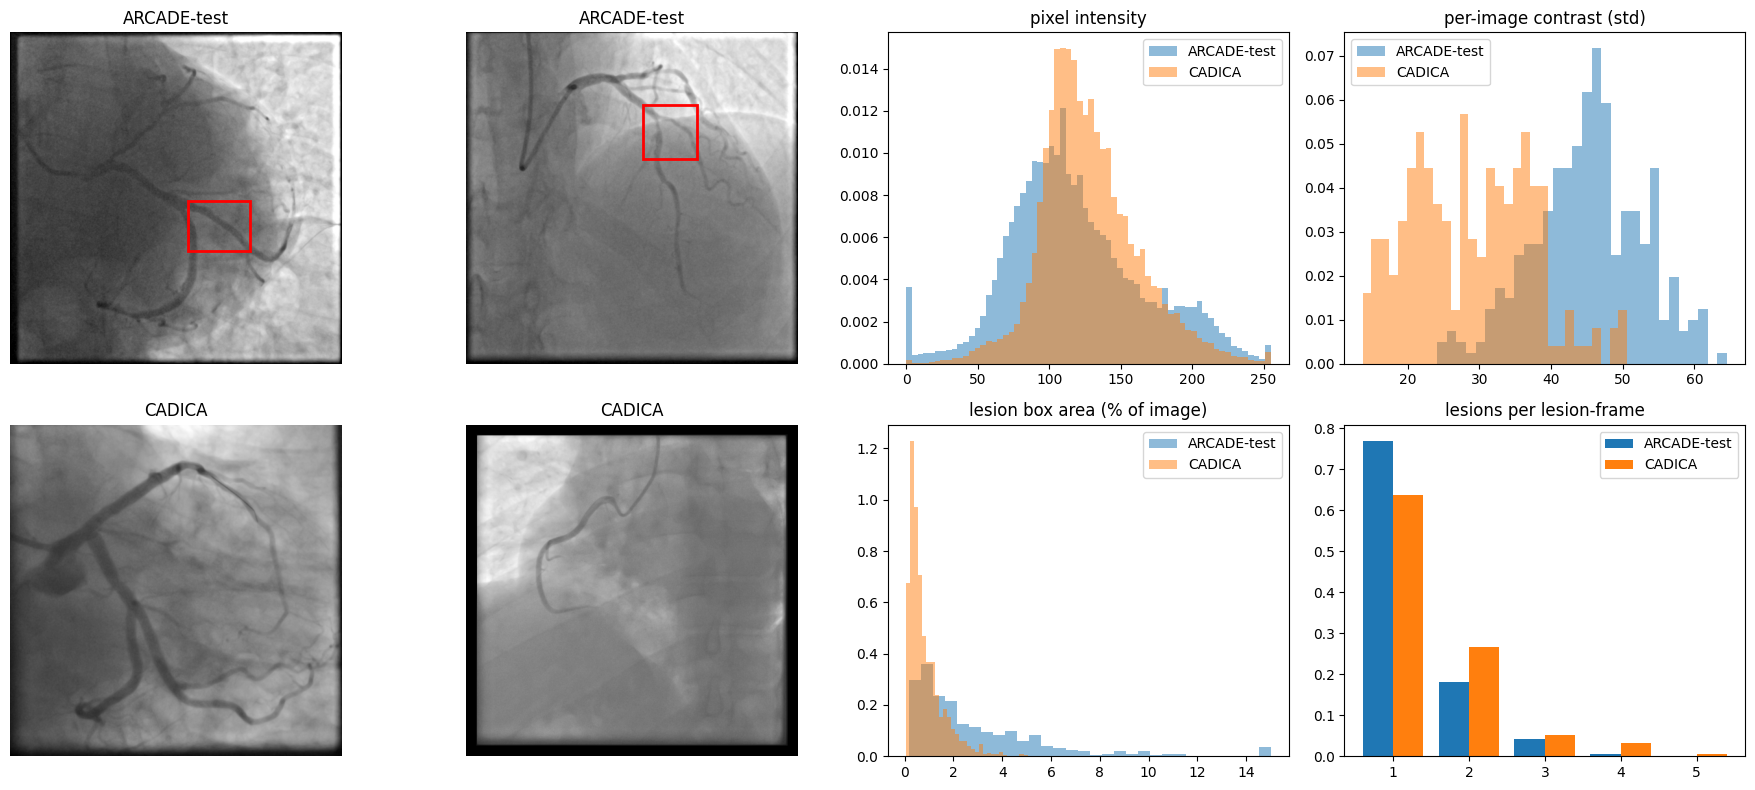

In [7]:
# ============================================================
# How different are the two datasets? (explains the domain shift)
# ============================================================
def box_area_pct(D):
    return [100 * (b[2] - b[0]) * (b[3] - b[1]) / IMG_SIZE ** 2 for bl in D["boxes"] for b in bl]
A_TEST = ARC["test"]
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
rng = np.random.default_rng(0)
for r_, (nm, D) in enumerate([("ARCADE-test", A_TEST), ("CADICA", CAD)]):
    for c_, i in enumerate(rng.choice(len(D["imgs"]), 2, replace=False)):
        ax[r_, c_].imshow(D["imgs"][i], cmap="gray"); ax[r_, c_].axis("off")
        for b in D["boxes"][i]:
            ax[r_, c_].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=2))
        ax[r_, c_].set_title(f"{nm}")
for nm, D, col in [("ARCADE-test", A_TEST, "C0"), ("CADICA", CAD, "C1")]:
    sub = D["imgs"][::max(1, len(D["imgs"]) // 200)]
    ax[0, 2].hist(sub.reshape(-1)[::17], bins=64, alpha=.5, density=True, label=nm, color=col)
    ax[0, 3].hist([i.std() for i in sub], bins=30, alpha=.5, density=True, label=nm, color=col)
    ax[1, 2].hist(np.clip(box_area_pct(D), 0, 15), bins=30, alpha=.5, density=True, label=nm, color=col)
ax[0, 2].set_title("pixel intensity"); ax[0, 3].set_title("per-image contrast (std)")
ax[1, 2].set_title("lesion box area (% of image)")
cnt = [Counter(len(b) for b, k in zip(D["boxes"], D["kinds"]) if k == "lesion") for D in (A_TEST, CAD)]
ax[1, 3].bar(np.arange(1, 6) - .2, [cnt[0].get(k, 0) / max(sum(cnt[0].values()), 1) for k in range(1, 6)], .4, label="ARCADE-test")
ax[1, 3].bar(np.arange(1, 6) + .2, [cnt[1].get(k, 0) / max(sum(cnt[1].values()), 1) for k in range(1, 6)], .4, label="CADICA")
ax[1, 3].set_title("lesions per lesion-frame")
for a in (ax[0, 2], ax[0, 3], ax[1, 2], ax[1, 3]): a.legend()
plt.tight_layout(); print("=== SS-2: dataset comparison ==="); plt.show()

## Model: DeepLabV3+ (ResNet101) trained on ARCADE
Loads your saved checkpoint if it exists, otherwise trains with the same recipe as before (two learning rates, BCE + Tversky, cosine schedule).

In [8]:
class NormalizedSegModel(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        return self.net((x - self.mean) / self.std)

def build_model(encoder_weights="imagenet"):
    net = smp.DeepLabV3Plus(encoder_name="resnet101", encoder_weights=encoder_weights, in_channels=3, classes=1)
    return NormalizedSegModel(net)

def tversky_loss(logits, targets, alpha=0.5, beta=0.5, eps=1e-6):
    p = torch.sigmoid(logits).view(logits.size(0), -1); t = targets.view(targets.size(0), -1)
    TP = (p * t).sum(1); FP = (p * (1 - t)).sum(1); FN = ((1 - p) * t).sum(1)
    return 1 - ((TP + eps) / (TP + alpha * FP + beta * FN + eps)).mean()

class SegLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(POS_WEIGHT)))
    def forward(self, lo, t): return 0.5 * self.bce(lo, t) + 0.5 * tversky_loss(lo, t)

class ArrDS(Dataset):
    def __init__(self, imgs, masks, tf=None): self.imgs, self.masks, self.tf = imgs, masks, tf
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i):
        img = np.repeat(self.imgs[i][..., None], 3, 2); m = self.masks[i].astype(np.float32)
        if self.tf is not None:
            o = self.tf(image=img, mask=m); img, m = o["image"], o["mask"]
        return (torch.from_numpy(img.astype(np.float32) / 255.0).permute(2, 0, 1), torch.from_numpy(m).unsqueeze(0))

def batch_dice(logits, targets, thr=0.5, eps=1e-6):
    p = (torch.sigmoid(logits) > thr).float().view(logits.size(0), -1); t = targets.view(targets.size(0), -1)
    return ((2 * (p * t).sum(1) + eps) / (p.sum(1) + t.sum(1) + eps)).mean().item()

def train_model():
    tf = A.Compose([A.HorizontalFlip(p=0.5),
                    A.Affine(rotate=(-10, 10), translate_percent=(0.0, 0.10), scale=(0.85, 1.15), shear=(-2, 2), p=0.7),
                    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
                    A.GaussNoise(p=0.2)])
    tl = DataLoader(ArrDS(ARC["train"]["imgs"], ARC["train"]["masks"], tf), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=True)
    vl = DataLoader(ArrDS(ARC["val"]["imgs"], ARC["val"]["masks"]), batch_size=BATCH_SIZE, num_workers=2)
    m = build_model("imagenet").to(DEVICE); crit = SegLoss().to(DEVICE)
    enc = list(m.net.encoder.parameters()); ids = {id(p) for p in enc}
    dec = [p for p in m.parameters() if id(p) not in ids]
    opt = torch.optim.AdamW([{"params": enc, "lr": LR_ENCODER}, {"params": dec, "lr": LR_DECODER}], weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = GradScaler("cuda", enabled=USE_CUDA)
    best, bad = -1, 0; CKPT_PATH.parent.mkdir(parents=True, exist_ok=True)
    for ep in range(1, EPOCHS + 1):
        m.train(); tot = 0
        for x, y in tl:
            x, y = x.to(DEVICE), y.to(DEVICE); opt.zero_grad()
            with autocast("cuda", enabled=USE_CUDA): lo = m(x)
            loss = crit(lo.float(), y); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item() * x.size(0)
        sch.step(); m.eval(); ds, n = 0, 0
        with torch.no_grad():
            for x, y in vl:
                x, y = x.to(DEVICE), y.to(DEVICE); ds += batch_dice(m(x).float(), y) * x.size(0); n += x.size(0)
        vd = ds / n; print(f"epoch {ep:3d}/{EPOCHS} loss {tot/len(tl.dataset):.4f} val_dice {vd:.4f}")
        if vd > best: best, bad = vd, 0; torch.save(m.state_dict(), CKPT_PATH)
        else:
            bad += 1
            if bad >= PATIENCE: print("early stop"); break
    return best

if CKPT_PATH.exists() and not FORCE_RETRAIN:
    print("Loading checkpoint:", CKPT_PATH)
else:
    print("No checkpoint (or FORCE_RETRAIN) -> training. Best val Dice:", train_model())

model = build_model(None).to(DEVICE)
model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
model.eval()
for p in model.parameters(): p.requires_grad_(True)     # needed by Grad-CAM later
print("Model ready. Params (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 1))

Loading checkpoint: /content/work/dl3_best.pt
Model ready. Params (M): 45.7


## Inference utilities: probability maps, instances, AdaBN
Lesion **instances** = connected components of the thresholded probability map (small blobs removed), scored by mean probability. Boxes are derived from these components.

In [9]:
def percentile_stretch(g):
    lo, hi = np.percentile(g, (1, 99))
    if hi - lo < 5: return g
    return np.clip((g.astype(np.float32) - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)

@torch.no_grad()
def predict_probs(m, gray_list, tta=True, stretch=False):
    """gray_list: list/array of HxW uint8. Returns float16 array (N,H,W)."""
    m.eval()
    arr = [percentile_stretch(g) if stretch else g for g in gray_list]
    x = torch.from_numpy(np.stack(arr)).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(DEVICE)
    with autocast("cuda", enabled=USE_CUDA):
        p = torch.sigmoid(m(x).float())
        if tta:
            pf = torch.sigmoid(m(torch.flip(x, dims=[3])).float())
            p = (p + torch.flip(pf, dims=[3])) / 2
    return p[:, 0].cpu().numpy().astype(np.float16)

def adapt_bn(m, imgs, stretch=False, bs=16, max_imgs=800, seed=0):
    """AdaBN: re-estimate BatchNorm statistics on unlabeled target images. No labels, no weight updates."""
    mm = copy.deepcopy(m).to(DEVICE).eval()
    for mod in mm.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.reset_running_stats(); mod.momentum = None; mod.train()
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(imgs))[:max_imgs]
    with torch.no_grad():
        for s in range(0, len(idx), bs):
            b = idx[s:s + bs]
            if len(b) < 2: continue
            arr = [percentile_stretch(imgs[i]) if stretch else imgs[i] for i in b]
            x = torch.from_numpy(np.stack(arr)).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(DEVICE)
            mm(x)
    mm.eval()
    return mm

def extract_instances(prob, thr, min_area, max_inst=99):
    b = (prob > thr).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
    out = []
    for i in range(1, n):
        x, y, w, h, a = stats[i]
        if a < min_area: continue
        crop = lab[y:y + h, x:x + w] == i
        pv = prob[y:y + h, x:x + w][crop].astype(np.float32)
        out.append(dict(box=(int(x), int(y), int(x + w), int(y + h)), area=int(a), score=float(pv.mean()),
                        maxp=float(pv.max()), crop=crop))
    out.sort(key=lambda d: -d["score"])
    return out[:max_inst]

def binarize_filter(prob, thr, min_area):
    b = (prob > thr).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
    keep = np.zeros(n, bool); keep[1:] = stats[1:, 4] >= min_area
    return keep[lab]

def dice_np(a, b, eps=1e-6):
    return (2 * np.logical_and(a, b).sum() + eps) / (a.sum() + b.sum() + eps)

def run_variant(m, imgs, thr, min_area, stretch=False, masks=None, bs=16, max_inst=99):
    insts, dices = [], []
    for s in tqdm(range(0, len(imgs), bs), leave=False):
        probs = predict_probs(m, imgs[s:s + bs], tta=USE_TTA, stretch=stretch)
        for j, p in enumerate(probs):
            p = p.astype(np.float32)
            insts.append(extract_instances(p, thr, min_area, max_inst))
            if masks is not None: dices.append(dice_np(binarize_filter(p, thr, min_area), masks[s + j] > 0))
    return insts, (float(np.mean(dices)) if dices else None)

# ---- ARCADE-train lesion size -> small-blob filter; ARCADE-val -> threshold (never the test sets) ----
areas = [r.area for mk in ARC["train"]["masks"] for r in regionprops(cv2.connectedComponents((mk > 0).astype(np.uint8), connectivity=8)[1])]
MIN_AREA = int(np.percentile(areas, MIN_AREA_PERCENTILE))
val_probs = np.concatenate([predict_probs(model, ARC["val"]["imgs"][s:s + 16], tta=USE_TTA) for s in range(0, len(ARC["val"]["imgs"]), 16)])
sweep = []
for t in THR_GRID:
    d = np.mean([dice_np(binarize_filter(p.astype(np.float32), t, MIN_AREA), mk > 0) for p, mk in zip(val_probs, ARC["val"]["masks"])])
    sweep.append((float(t), float(d)))
THR = max(sweep, key=lambda z: z[1])[0]
print(f"MIN_AREA={MIN_AREA}px | threshold chosen on ARCADE-val (mean Dice): {THR}")
print([f"{t:.2f}:{d:.3f}" for t, d in sweep])
del val_probs

MIN_AREA=371px | threshold chosen on ARCADE-val (mean Dice): 0.4
['0.20:0.604', '0.25:0.607', '0.30:0.610', '0.35:0.611', '0.40:0.612', '0.45:0.609', '0.50:0.602', '0.55:0.589', '0.60:0.575', '0.65:0.567', '0.70:0.564', '0.75:0.561', '0.80:0.555']


## Evaluation utilities (box-level, three matching rules, patient-cluster bootstrap)
* **IoU≥0.5** – strict standard detection rule.
* **IoU≥0.1** – lenient (what your U-Net notebooks used).
* **hit** – predicted box centre inside the GT box, or GT centre inside the predicted box (clinically: "did it point at the right place?").

Greedy matching by descending score, each GT matched once. Frame metrics on CADICA use the *normal* (lesion-free) frames too, so **false alarms on healthy frames are counted**.

In [10]:
CRITS = ["i50", "i10", "hit"]

def box_iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy; u = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / u if u > 0 else 0.0

def center_hit(p, g):
    pc = ((p[0] + p[2]) / 2, (p[1] + p[3]) / 2); gc = ((g[0] + g[2]) / 2, (g[1] + g[3]) / 2)
    return (g[0] <= pc[0] <= g[2] and g[1] <= pc[1] <= g[3]) or (p[0] <= gc[0] <= p[2] and p[1] <= gc[1] <= p[3])

def match_frame(pboxes, gboxes, crit):
    used, tp, gt_hit = set(), [False] * len(pboxes), [False] * len(gboxes)
    for i, pb in enumerate(pboxes):                      # pboxes sorted by score (desc)
        best, bj = -1.0, -1
        for j, gb in enumerate(gboxes):
            if j in used: continue
            iou = box_iou(pb, gb)
            if crit == "hit": ok, s = center_hit(pb, gb), 1.0 + iou
            else:             ok, s = iou >= (0.5 if crit == "i50" else 0.1), iou
            if ok and s > best: best, bj = s, j
        if bj >= 0: used.add(bj); tp[i] = True; gt_hit[bj] = True
    return tp, gt_hit

def evaluate(insts, gboxes, groups, kinds, glabels):
    rows, grows = [], []
    for k, (ins, gb) in enumerate(zip(insts, gboxes)):
        pb = [i["box"] for i in ins]
        row = dict(group=groups[k], kind=kinds[k], n_pred=len(pb), n_gt=len(gb))
        flags = {}
        for c in CRITS:
            tp, gh = match_frame(pb, gb, c); flags[c] = gh
            row[f"tp_{c}"] = sum(tp); row[f"fp_{c}"] = len(pb) - sum(tp); row[f"fn_{c}"] = len(gb) - sum(gh)
        rows.append(row)
        for j in range(len(gb)):
            grows.append(dict(group=groups[k], label=glabels[k][j], sev=sev_bin(glabels[k][j]),
                              m_i50=flags["i50"][j], m_i10=flags["i10"][j], m_hit=flags["hit"][j]))
    return pd.DataFrame(rows), pd.DataFrame(grows)

def prf(tp, fp, fn):
    p = tp / max(tp + fp, 1e-9); r = tp / max(tp + fn, 1e-9); return p, r, 2 * p * r / max(p + r, 1e-9)

def boot_f1(df, crit, n=N_BOOT, seed=0):
    g = df.groupby("group")[[f"tp_{crit}", f"fp_{crit}", f"fn_{crit}"]].sum().values
    rng = np.random.default_rng(seed)
    f = [prf(*g[rng.integers(0, len(g), len(g))].sum(0))[2] for _ in range(n)]
    return np.percentile(f, [2.5, 97.5])

def summarize(dfF, dfG, dice=None):
    out = {}
    for c in CRITS:
        p, r, f = prf(dfF[f"tp_{c}"].sum(), dfF[f"fp_{c}"].sum(), dfF[f"fn_{c}"].sum())
        lo, hi = boot_f1(dfF, c)
        out.update({f"P_{c}": p, f"R_{c}": r, f"F1_{c}": f, f"F1_{c}_lo": lo, f"F1_{c}_hi": hi})
    les, nor = dfF[dfF.kind == "lesion"], dfF[dfF.kind == "normal"]
    out["frame_sens"] = float((les.tp_hit > 0).mean()) if len(les) else np.nan
    out["frame_spec"] = float((nor.n_pred == 0).mean()) if len(nor) else np.nan
    out["preds_per_frame"] = float(dfF.n_pred.mean()); out["dice_px"] = dice
    return out
print("Evaluation utilities ready.")

Evaluation utilities ready.


# PART A – Cross-dataset test (Objective 3)
Four variants, evaluated with the **same threshold / filter chosen on ARCADE-val** (nothing is tuned on CADICA):

| variant | what it is |
|---|---|
| `zero_shot` | ARCADE model, unchanged |
| `stretch` | + per-image 1-99 percentile intensity stretch |
| `adabn` | + BatchNorm statistics re-estimated on the unlabeled target images (no labels) |
| `adabn+stretch` | both |

AdaBN is also applied to ARCADE-test as a **control** (it should not change much there).

In [11]:
VARIANTS = {"zero_shot": dict(adapt=False, stretch=False), "stretch": dict(adapt=False, stretch=True),
            "adabn": dict(adapt=True, stretch=False), "adabn+stretch": dict(adapt=True, stretch=True)}
DATASETS = {"ARCADE-test": A_TEST, "CADICA": CAD}

RES, FR, ADAPTED = {}, {}, {}
for dname, D in DATASETS.items():
    for vname, cfg in VARIANTS.items():
        m = adapt_bn(model, D["imgs"], stretch=cfg["stretch"]) if cfg["adapt"] else model
        if cfg["adapt"]: ADAPTED[(dname, vname)] = m
        insts, dice = run_variant(m, D["imgs"], THR, MIN_AREA, stretch=cfg["stretch"], masks=D["masks"])
        dfF, dfG = evaluate(insts, D["boxes"], D["groups"], D["kinds"], D["labels"])
        RES[(dname, vname)] = summarize(dfF, dfG, dice); FR[(dname, vname)] = (dfF, dfG)
        print(f"{dname:12s} {vname:14s} F1@0.1={RES[(dname, vname)]['F1_i10']:.3f}  F1@0.5={RES[(dname, vname)]['F1_i50']:.3f}")

  0%|          | 0/19 [00:00<?, ?it/s]

ARCADE-test  zero_shot      F1@0.1=0.703  F1@0.5=0.281


  0%|          | 0/19 [00:00<?, ?it/s]

ARCADE-test  stretch        F1@0.1=0.715  F1@0.5=0.288


  0%|          | 0/19 [00:00<?, ?it/s]

ARCADE-test  adabn          F1@0.1=0.727  F1@0.5=0.315


... (6 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

CADICA       adabn          F1@0.1=0.422  F1@0.5=0.128


  0%|          | 0/139 [00:00<?, ?it/s]

CADICA       adabn+stretch  F1@0.1=0.428  F1@0.5=0.125


=== SS-3: cross-dataset results (box-level; ARCADE-test vs CADICA) ===
    dataset       variant  P@.5  R@.5  F1@.5      F1@.1 [95% CI]  P@.1  R@.1  F1 hit  frame sens  frame spec  preds/frame
ARCADE-test     zero_shot 0.256 0.311  0.281 0.703 [0.671,0.737] 0.641 0.777   0.735       0.953         NaN        1.560
ARCADE-test       stretch 0.265 0.316  0.288 0.715 [0.684,0.748] 0.657 0.785   0.741       0.947         NaN        1.537
ARCADE-test         adabn 0.293 0.339  0.315 0.727 [0.695,0.760] 0.678 0.785   0.744       0.940         NaN        1.490
ARCADE-test adabn+stretch 0.283 0.326  0.303 0.722 [0.683,0.755] 0.674 0.777   0.744       0.943         NaN        1.483
     CADICA     zero_shot 0.097 0.137  0.113 0.419 [0.373,0.466] 0.358 0.506   0.516       0.844       0.146        1.498
     CADICA       stretch 0.121 0.172  0.142 0.445 [0.397,0.500] 0.379 0.538   0.518       0.834       0.162        1.503
     CADICA         adabn 0.108 0.157  0.128 0.422 [0.380,0.470] 0.356 0.51

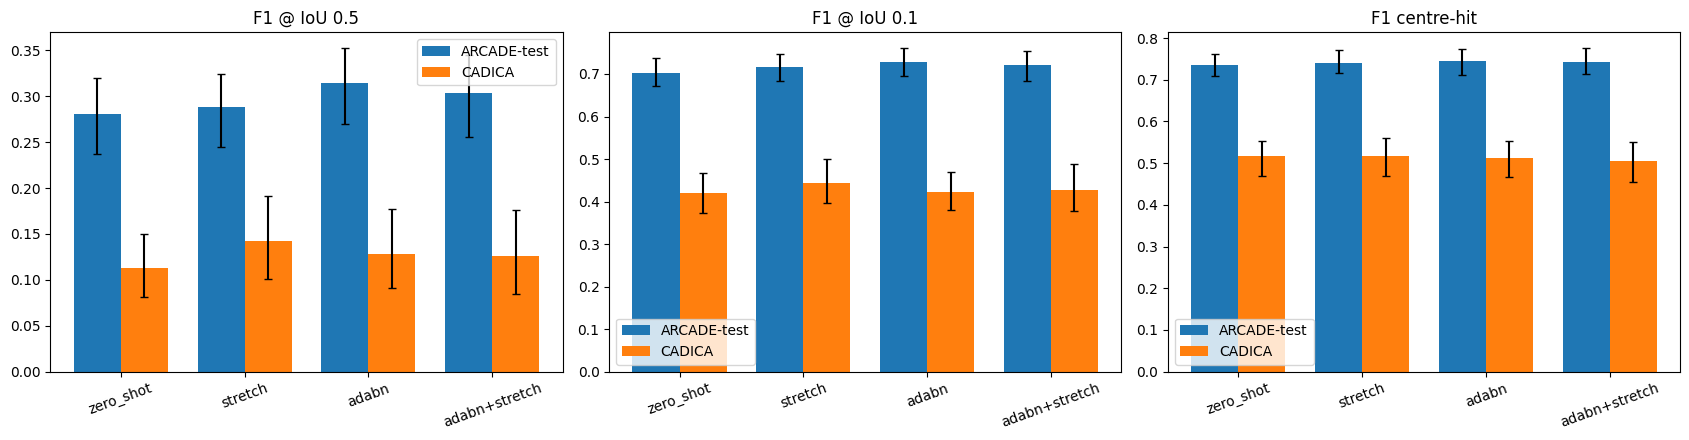

In [12]:
rows = []
for (dname, vname), r in RES.items():
    rows.append({"dataset": dname, "variant": vname,
                 "P@.5": r["P_i50"], "R@.5": r["R_i50"], "F1@.5": r["F1_i50"],
                 "F1@.1 [95% CI]": f"{r['F1_i10']:.3f} [{r['F1_i10_lo']:.3f},{r['F1_i10_hi']:.3f}]",
                 "P@.1": r["P_i10"], "R@.1": r["R_i10"], "F1 hit": r["F1_hit"],
                 "frame sens": r["frame_sens"], "frame spec": r["frame_spec"], "preds/frame": r["preds_per_frame"]})
TAB_A = pd.DataFrame(rows)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("=== SS-3: cross-dataset results (box-level; ARCADE-test vs CADICA) ===")
print(TAB_A.round(3).to_string(index=False))

print("\n=== Drop ARCADE -> CADICA (F1; relative drop %) ===")
drop = []
for v in VARIANTS:
    for c in ["i50", "i10", "hit"]:
        a, b = RES[("ARCADE-test", v)][f"F1_{c}"], RES[("CADICA", v)][f"F1_{c}"]
        drop.append({"variant": v, "criterion": c, "ARCADE F1": a, "CADICA F1": b, "abs drop": a - b, "rel drop %": 100 * (a - b) / max(a, 1e-9)})
print(pd.DataFrame(drop).round(3).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for k, (c, ttl) in enumerate([("i50", "F1 @ IoU 0.5"), ("i10", "F1 @ IoU 0.1"), ("hit", "F1 centre-hit")]):
    w = 0.38; x = np.arange(len(VARIANTS))
    for o, dn in enumerate(["ARCADE-test", "CADICA"]):
        v = [RES[(dn, vn)][f"F1_{c}"] for vn in VARIANTS]
        lo = [max(0.0, RES[(dn, vn)][f"F1_{c}"] - RES[(dn, vn)][f"F1_{c}_lo"]) for vn in VARIANTS]
        hi = [max(0.0, RES[(dn, vn)][f"F1_{c}_hi"] - RES[(dn, vn)][f"F1_{c}"]) for vn in VARIANTS]
        ax[k].bar(x + (o - .5) * w, v, w, yerr=[lo, hi], capsize=3, label=dn)
    ax[k].set_xticks(x); ax[k].set_xticklabels(list(VARIANTS), rotation=20); ax[k].set_title(ttl); ax[k].legend()
plt.tight_layout(); print("=== SS-4: F1 by variant, 95% patient-cluster CI ==="); plt.show()

=== SS-5: CADICA recall by lesion severity (share of GT lesions found) ===
      variant severity  n_lesions  recall@IoU0.1  recall@hit  recall@IoU0.5
    zero_shot      <50       1126          0.459       0.583          0.095
    zero_shot    50-69        374          0.596       0.687          0.179
    zero_shot    70-89        372          0.586       0.728          0.151
    zero_shot     >=90        472          0.483       0.583          0.191
      stretch      <50       1126          0.469       0.584          0.111
      stretch    50-69        374          0.660       0.717          0.273
      stretch    70-89        372          0.626       0.702          0.180
      stretch     >=90        472          0.534       0.595          0.229
        adabn      <50       1126          0.449       0.583          0.096
        adabn    50-69        374          0.631       0.709          0.273
        adabn    70-89        372          0.621       0.739          0.156
        adabn

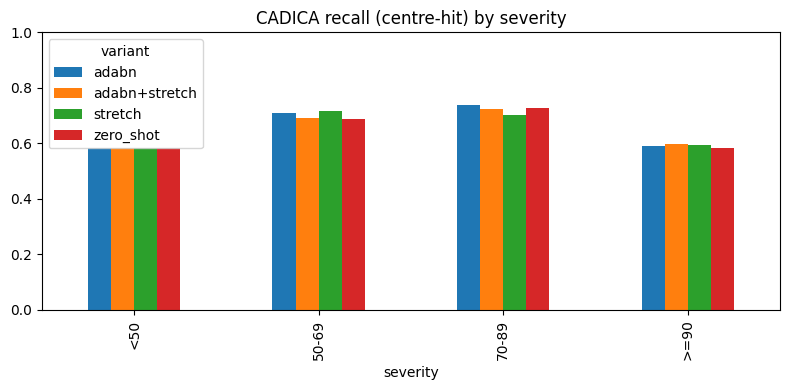

In [13]:
# Is the drop explained by lesion severity? (CADICA contains mild lesions; ARCADE annotates clinically relevant ones)
print("=== SS-5: CADICA recall by lesion severity (share of GT lesions found) ===")
sev_rows = []
for v in VARIANTS:
    g = FR[("CADICA", v)][1]
    for sb in ["<50", "50-69", "70-89", ">=90"]:
        s = g[g.sev == sb]
        if len(s): sev_rows.append({"variant": v, "severity": sb, "n_lesions": len(s),
                                    "recall@IoU0.1": s.m_i10.mean(), "recall@hit": s.m_hit.mean(), "recall@IoU0.5": s.m_i50.mean()})
SEV = pd.DataFrame(sev_rows)
print(SEV.round(3).to_string(index=False))
if len(SEV):
    piv = SEV.pivot(index="severity", columns="variant", values="recall@hit").reindex(["<50", "50-69", "70-89", ">=90"])
    piv.plot(kind="bar", figsize=(8, 4), title="CADICA recall (centre-hit) by severity"); plt.ylim(0, 1); plt.tight_layout(); plt.show()

=== SS-6: CADICA qualitative (red = GT, green = prediction) ===


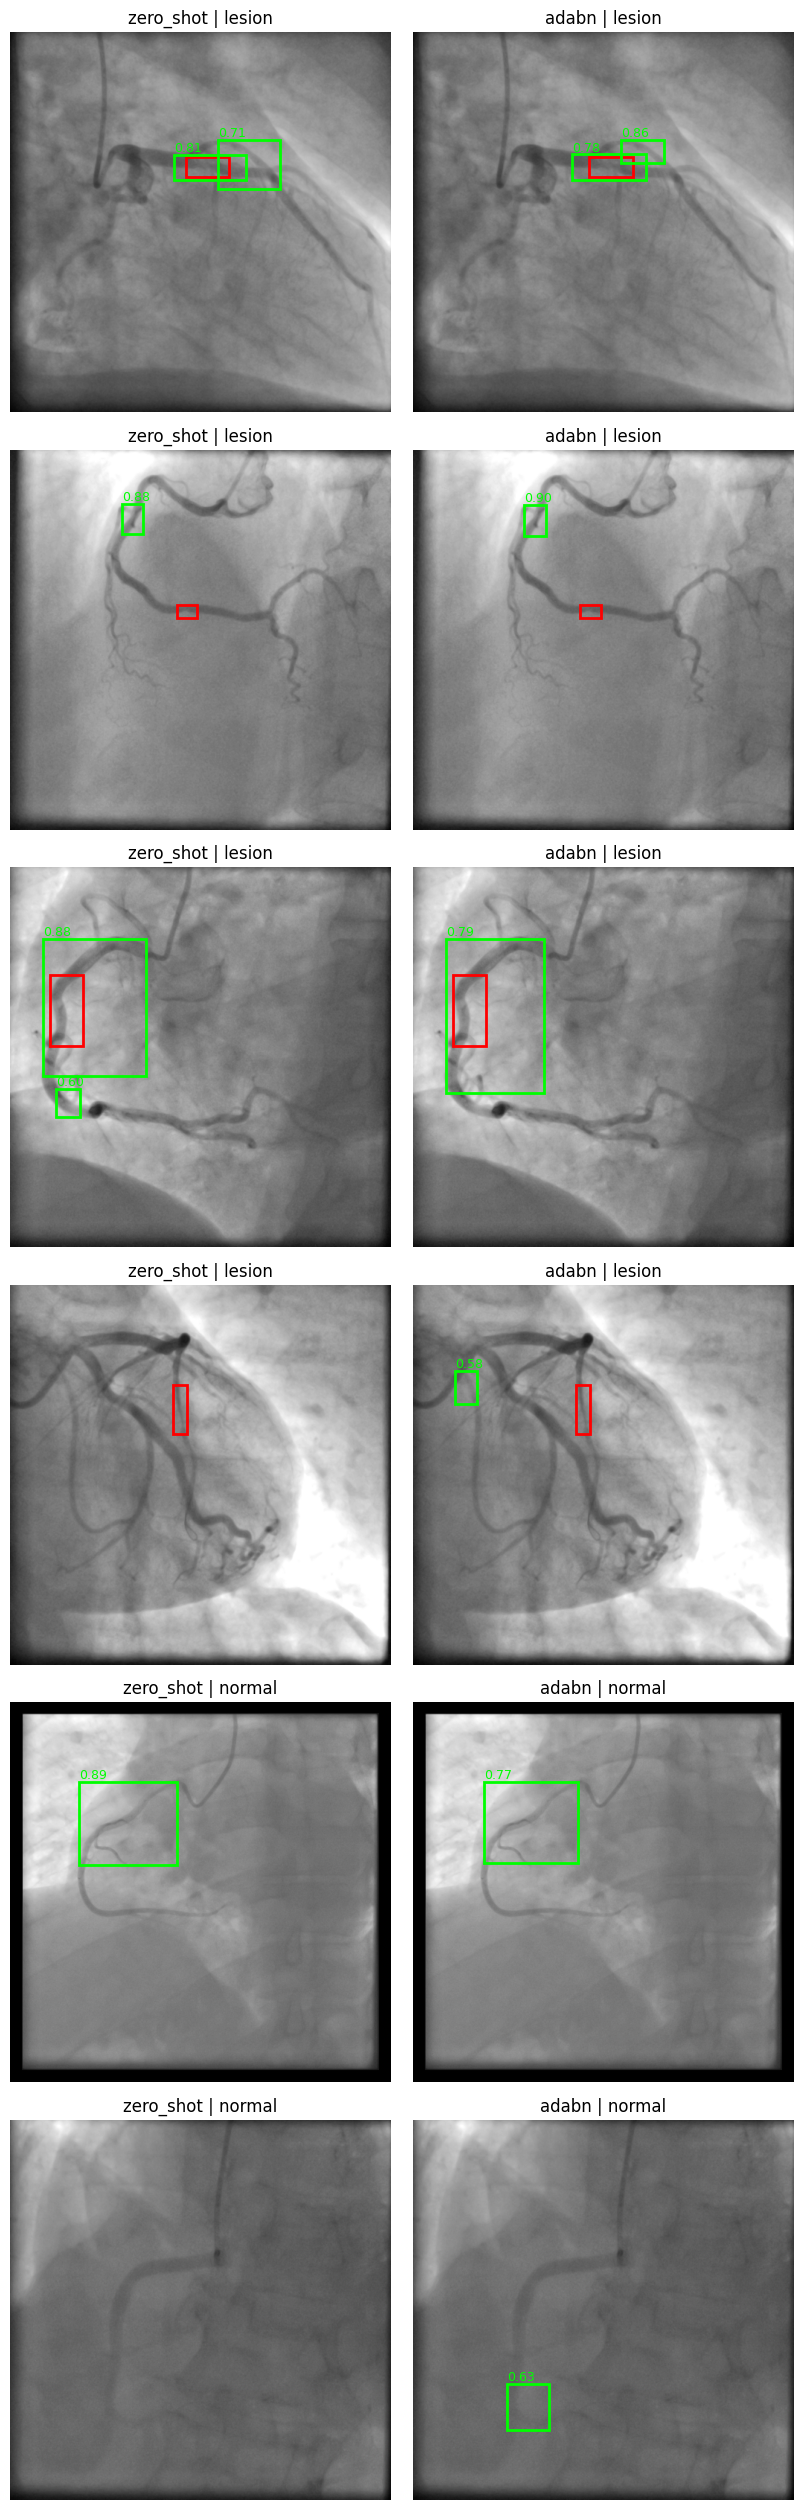

In [14]:
# Qualitative: CADICA frames, GT (red) vs prediction (green) for the zero-shot and the adapted model
def show_frames(vnames, n=6, seed=1):
    rng = np.random.default_rng(seed)
    les_idx = [i for i, k in enumerate(CAD["kinds"]) if k == "lesion"]; nor_idx = [i for i, k in enumerate(CAD["kinds"]) if k == "normal"]
    pick = list(rng.choice(les_idx, n - 2, replace=False)) + list(rng.choice(nor_idx, 2, replace=False))
    fig, ax = plt.subplots(len(pick), len(vnames), figsize=(4.2 * len(vnames), 4.2 * len(pick)))
    for r_, i in enumerate(pick):
        for c_, vn in enumerate(vnames):
            cfg = VARIANTS[vn]; m = ADAPTED.get(("CADICA", vn), model)
            g = percentile_stretch(CAD["imgs"][i]) if cfg["stretch"] else CAD["imgs"][i]
            ins = extract_instances(predict_probs(m, [CAD["imgs"][i]], USE_TTA, cfg["stretch"])[0].astype(np.float32), THR, MIN_AREA)
            a = ax[r_, c_]; a.imshow(g, cmap="gray"); a.axis("off")
            for b in CAD["boxes"][i]: a.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=2))
            for q in ins:
                b = q["box"]; a.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=2))
                a.text(b[0], max(b[1] - 4, 0), f"{q['score']:.2f}", color="lime", fontsize=9)
            a.set_title(f"{vn} | {CAD['kinds'][i]}")
    plt.tight_layout(); plt.show()
print("=== SS-6: CADICA qualitative (red = GT, green = prediction) ===")
show_frames(["zero_shot", "adabn"])

In [15]:
TAB_A.to_csv(OUT_DIR / "partA_cross_dataset_table.csv", index=False)
SEV.to_csv(OUT_DIR / "partA_cadica_severity_recall.csv", index=False)
print("Saved Part A tables to", OUT_DIR)

Saved Part A tables to /content/outputs


# PART B – Explainability that is measured (Objective 2)
**Seg-Grad-CAM** explains each *predicted lesion*: the target score is the mean logit inside that lesion's region; the CAM shows which feature locations drive it.

We then ask four questions, each with a number:
1. **Localisation** – does the CAM concentrate on the true lesion? (pointing game, energy lift vs chance)
2. **Faithfulness** – if we delete the CAM's top pixels, does the prediction collapse more than for random pixels? Also with the lesion itself excluded (*context-only* deletion): does the model rely on surrounding context?
3. **Sanity** – does the CAM change when we randomise the weights? (If not, it is not explaining the model.)
4. **Use** – do CAM features help to reject false positives?

In [16]:
class SegGradCAM:
    """Seg-Grad-CAM (Vinogradova et al. 2020): target = mean logit inside a region."""
    def __init__(self, m, target="decoder"):
        self.m, self.act = m, None
        layer = m.net.decoder if target == "decoder" else m.net.encoder.layer4
        self.h = layer.register_forward_hook(self._fwd)
    def _fwd(self, mod, inp, out):
        if isinstance(out, (list, tuple)): out = out[-1]
        self.act = out
    def close(self): self.h.remove()
    def run(self, gray, regions):
        x = torch.from_numpy(gray).float().div(255)[None, None].repeat(1, 3, 1, 1).to(DEVICE)
        cams = []
        with torch.enable_grad():
            self.m.eval()
            logits = self.m(x); act = self.act
            for i, reg in enumerate(regions):
                r = torch.from_numpy(reg.astype(np.float32)).to(DEVICE)
                score = (logits[0, 0] * r).sum() / (r.sum() + 1e-6)
                g = torch.autograd.grad(score, act, retain_graph=(i < len(regions) - 1))[0]
                w = g.mean((2, 3), keepdim=True)
                cam = F.relu((w * act).sum(1, keepdim=True))
                cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
                cam = cam - cam.min(); cam = cam / (cam.max() + 1e-8)
                cams.append(cam.detach().cpu().numpy())
        return cams

def full_mask(ins):
    reg = np.zeros((IMG_SIZE, IMG_SIZE), bool); x0, y0, x1, y1 = ins["box"]; reg[y0:y1, x0:x1] = ins["crop"]; return reg

K_RING = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31)); K_IN = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
K_CAM = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))

def _axis(rp, which):
    return float(getattr(rp, f"axis_{which}_length") if hasattr(rp, f"axis_{which}_length") else getattr(rp, f"{which}_axis_length"))

def inst_features(ins, gray, cam):
    reg = full_mask(ins); r8 = reg.astype(np.uint8)
    rp = regionprops(ins["crop"].astype(np.uint8))[0]
    outer = cv2.dilate(r8, K_RING).astype(bool); inner = cv2.dilate(r8, K_IN).astype(bool); ring = outer & ~inner
    g = gray.astype(np.float32)
    x0, y0, x1, y1 = ins["box"]
    c = cam; tot = c.sum() + 1e-8
    flat = np.sort(c.ravel())[::-1]; p = c.ravel() / tot; p = p[p > 0]
    dil = cv2.dilate(r8, K_CAM).astype(bool)
    return dict(
        area=math.log1p(ins["area"]), score=ins["score"], maxp=ins["maxp"],
        ecc=rp.eccentricity, solidity=rp.solidity, elong=_axis(rp, "major") / (_axis(rp, "minor") + 1e-6),
        contrast=float(g[ring].mean() - g[reg].mean()) if ring.any() else 0.0, in_std=float(g[reg].std()),
        dist_border=min(x0, y0, IMG_SIZE - x1, IMG_SIZE - y1) / IMG_SIZE,
        cam_in_ratio=float(c[reg].mean() / (c.mean() + 1e-8)), cam_energy_frac=float(c[dil].sum() / tot),
        cam_top1_share=float(flat[:int(0.01 * flat.size)].sum() / tot),
        cam_entropy=float(-(p * np.log(p)).sum() / np.log(c.size)) if len(p) else 1.0, cam_area_frac=float((c > 0.5).mean()))

F_BASIC = ["area", "score", "maxp", "ecc", "solidity", "elong", "contrast", "in_std", "dist_border"]
F_CTX   = ["n_inst", "score_rank", "score_rel"]
F_CAM   = ["cam_in_ratio", "cam_energy_frac", "cam_top1_share", "cam_entropy", "cam_area_frac"]
FSETS = {"score only": ["score"], "basic": F_BASIC, "basic+context": F_BASIC + F_CTX,
         "CAM only (+score)": ["score"] + F_CAM, "basic+context+CAM": F_BASIC + F_CTX + F_CAM}

def collect(m, D, stretch, tag, bs=8):
    eng = SegGradCAM(m, CAM_TARGET); inst_all, rows = [], []
    for s in tqdm(range(0, len(D["imgs"]), bs), desc=tag):
        probs = predict_probs(m, D["imgs"][s:s + bs], USE_TTA, stretch)
        for j, p in enumerate(probs):
            fi = s + j
            g = percentile_stretch(D["imgs"][fi]) if stretch else D["imgs"][fi]
            ins = extract_instances(p.astype(np.float32), CAND_THR, MIN_AREA, MAX_INST_PER_FRAME)
            inst_all.append(ins)
            if not ins: continue
            cams = eng.run(g, [full_mask(i) for i in ins]); mx = max(i["score"] for i in ins)
            for rk, (i, cam) in enumerate(zip(ins, cams)):
                f = inst_features(i, g, cam)
                f.update(fi=fi, group=D["groups"][fi], n_inst=len(ins), score_rank=rk, score_rel=i["score"] / mx)
                rows.append(f)
    eng.close()
    df = pd.DataFrame(rows); lab = {}
    for fi, ins in enumerate(inst_all):
        if not ins: continue
        pb = [i["box"] for i in ins]
        t10, _ = match_frame(pb, D["boxes"][fi], "i10"); t50, _ = match_frame(pb, D["boxes"][fi], "i50"); th, _ = match_frame(pb, D["boxes"][fi], "hit")
        for rk in range(len(ins)): lab[(fi, rk)] = (t10[rk], t50[rk], th[rk])
    df["y10"] = [int(lab[(a, b)][0]) for a, b in zip(df.fi, df.score_rank)]
    df["y50"] = [int(lab[(a, b)][1]) for a, b in zip(df.fi, df.score_rank)]
    df["yhit"] = [int(lab[(a, b)][2]) for a, b in zip(df.fi, df.score_rank)]
    return dict(inst=inst_all, df=df)

B_CFG = VARIANTS[B_VARIANT]
M_CAD = ADAPTED.get(("CADICA", B_VARIANT), model)
B_SETS = {"ARCADE-val":  (ARC["val"], model, False), "ARCADE-test": (A_TEST, model, False), "CADICA": (CAD, M_CAD, B_CFG["stretch"])}
CAND = {k: collect(m, D, st, k) for k, (D, m, st) in B_SETS.items()}
for k, c in CAND.items():
    print(f"{k:12s} candidates: {len(c['df'])} | TP@IoU0.1: {int(c['df'].y10.sum())} | FP: {int((1 - c['df'].y10).sum())}")

ARCADE-val:   0%|          | 0/25 [00:00<?, ?it/s]

ARCADE-test:   0%|          | 0/38 [00:00<?, ?it/s]

CADICA:   0%|          | 0/277 [00:00<?, ?it/s]

ARCADE-val   candidates: 289 | TP@IoU0.1: 221 | FP: 68
ARCADE-test  candidates: 474 | TP@IoU0.1: 304 | FP: 170
CADICA       candidates: 3564 | TP@IoU0.1: 1203 | FP: 2361


=== SS-7: Seg-Grad-CAM examples (red = GT box, green = predicted lesion; bottom row = CAM) ===


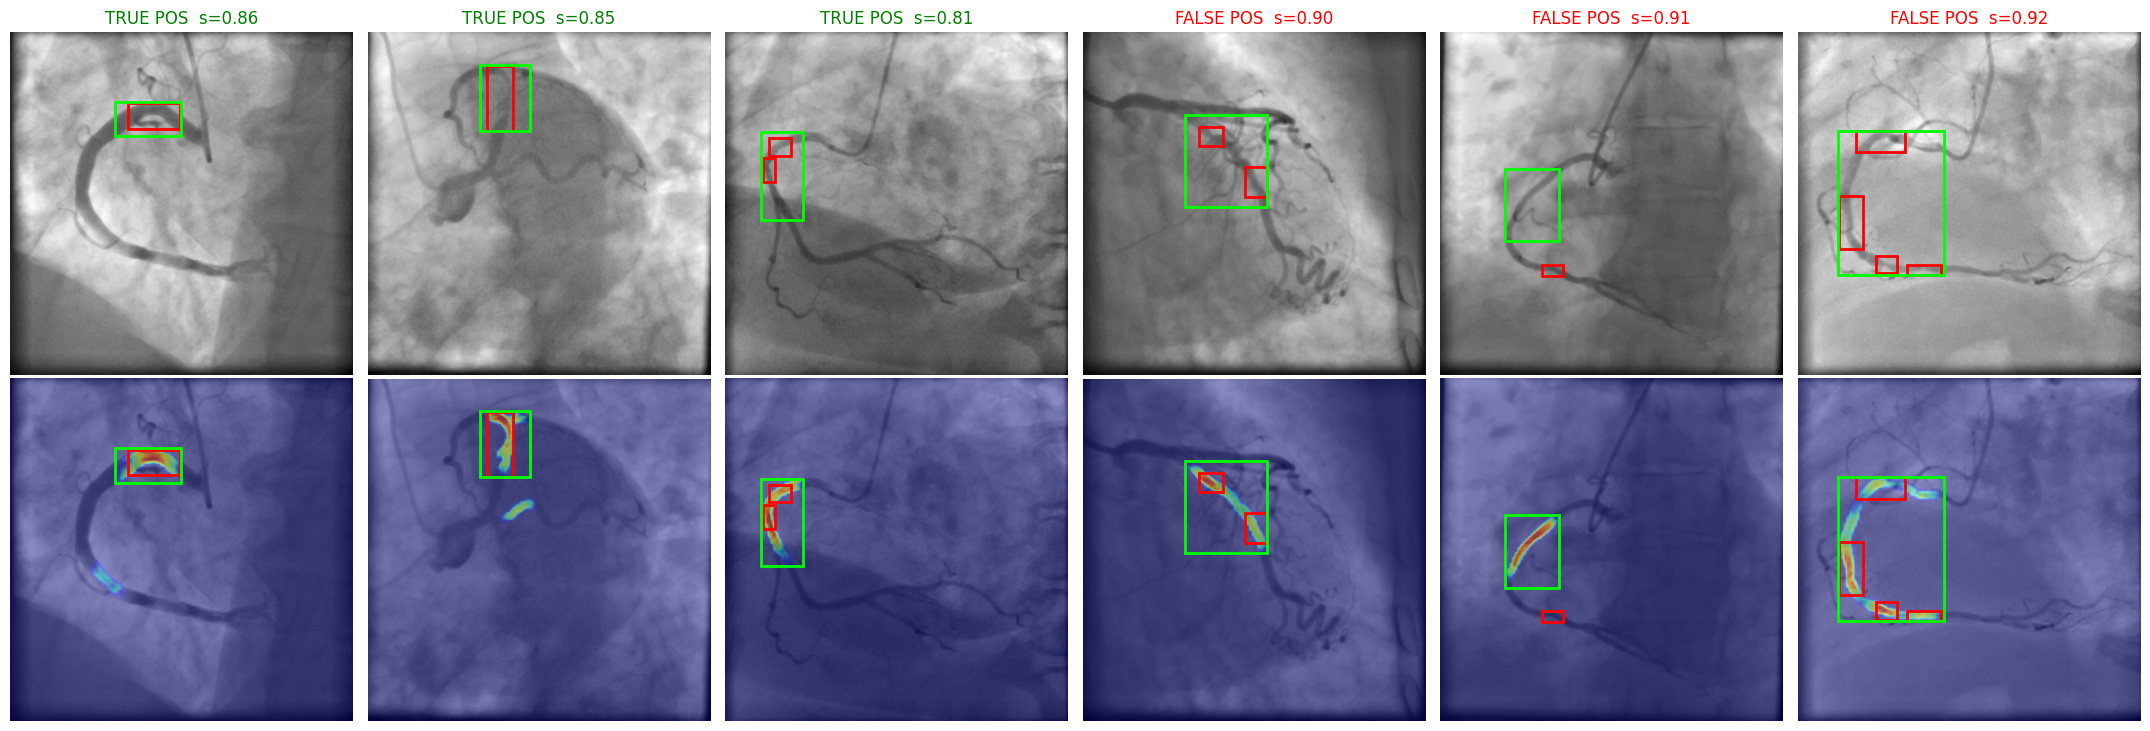

In [17]:
# ---- SS-7: what do the explanations look like? 3 true positives and 3 false positives on CADICA ----
def show_cam_examples(name="CADICA", n_each=3, seed=3):
    D, m, st = B_SETS[name]; df = CAND[name]["df"]; inst_all = CAND[name]["inst"]
    rng = np.random.default_rng(seed)
    tp = df[df.y10 == 1].sort_values("score", ascending=False); fp = df[df.y10 == 0].sort_values("score", ascending=False)
    pick = list(tp.sample(min(n_each, len(tp)), random_state=seed).itertuples()) + list(fp.head(40).sample(min(n_each, len(fp.head(40))), random_state=seed).itertuples())
    eng = SegGradCAM(m, CAM_TARGET)
    fig, ax = plt.subplots(2, len(pick), figsize=(3.6 * len(pick), 7.4))
    for c_, r in enumerate(pick):
        ins = inst_all[r.fi][r.score_rank]; g = percentile_stretch(D["imgs"][r.fi]) if st else D["imgs"][r.fi]
        cam = eng.run(g, [full_mask(ins)])[0]
        for rr in range(2):
            ax[rr, c_].imshow(g, cmap="gray"); ax[rr, c_].axis("off")
            for b in D["boxes"][r.fi]: ax[rr, c_].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=2))
            b = ins["box"]; ax[rr, c_].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=2))
        ax[1, c_].imshow(cam, cmap="jet", alpha=0.45)
        ax[0, c_].set_title(("TRUE POS" if r.y10 else "FALSE POS") + f"  s={r.score:.2f}", color="green" if r.y10 else "red")
    eng.close(); plt.tight_layout(); plt.show()
print("=== SS-7: Seg-Grad-CAM examples (red = GT box, green = predicted lesion; bottom row = CAM) ===")
show_cam_examples()

=== SS-8: single-feature AUC for separating TP vs FP candidates (0.5 = useless) ===
        feature   group  ARCADE-val  ARCADE-test  CADICA
          score   basic       0.757        0.837   0.742
           maxp   basic       0.739        0.821   0.722
cam_energy_frac     CAM       0.721        0.855   0.656
      score_rel context       0.698        0.820   0.641
     score_rank context       0.694        0.810   0.631
   cam_in_ratio     CAM       0.683        0.726   0.630
           area   basic       0.689        0.819   0.628
         n_inst context       0.675        0.769   0.600
         in_std   basic       0.595        0.688   0.561
            ecc   basic       0.595        0.545   0.555
          elong   basic       0.595        0.545   0.555
       solidity   basic       0.622        0.781   0.552
    dist_border   basic       0.505        0.510   0.533
  cam_area_frac     CAM       0.535        0.503   0.529
 cam_top1_share     CAM       0.505        0.569   0.519
    

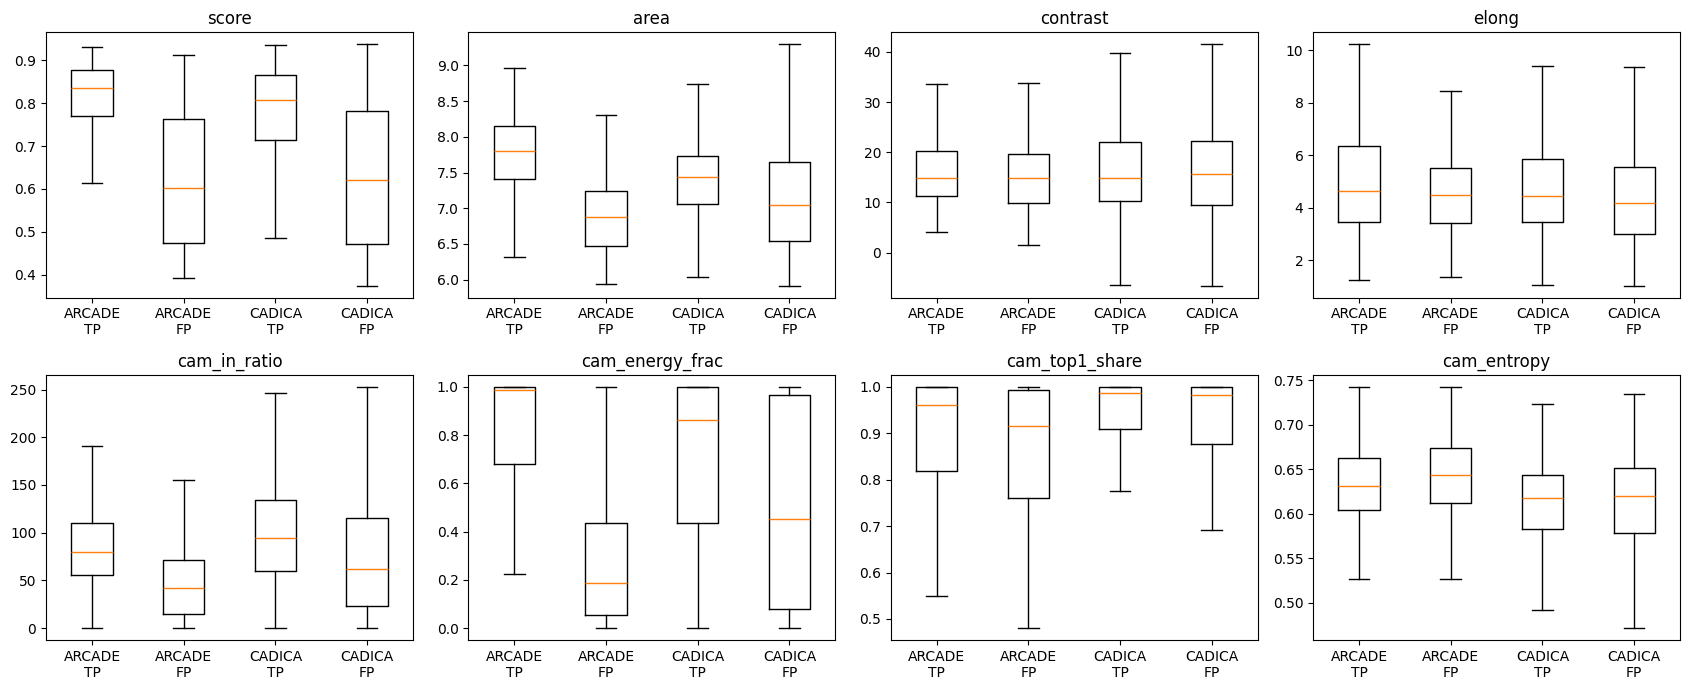

In [18]:
# ---- SS-8: do true and false positives differ? (single-feature AUC + distributions) ----
def single_auc(df, f):
    if df.y10.nunique() < 2: return np.nan
    a = roc_auc_score(df.y10, df[f].fillna(0)); return max(a, 1 - a)
rows = []
for f in F_BASIC + F_CTX + F_CAM:
    rows.append({"feature": f, "group": "CAM" if f in F_CAM else "context" if f in F_CTX else "basic",
                 **{k: single_auc(CAND[k]["df"], f) for k in CAND}})
AUC1 = pd.DataFrame(rows).sort_values("CADICA", ascending=False)
print("=== SS-8: single-feature AUC for separating TP vs FP candidates (0.5 = useless) ===")
print(AUC1.round(3).to_string(index=False))

show = ["score", "area", "contrast", "elong", "cam_in_ratio", "cam_energy_frac", "cam_top1_share", "cam_entropy"]
fig, ax = plt.subplots(2, 4, figsize=(17, 7))
for a, f in zip(ax.ravel(), show):
    data, lbl = [], []
    for k in ["ARCADE-test", "CADICA"]:
        d = CAND[k]["df"]
        for y, nm in [(1, "TP"), (0, "FP")]: data.append(d.loc[d.y10 == y, f].values); lbl.append(f"{k[:6]}\n{nm}")
    a.boxplot(data, showfliers=False); a.set_xticklabels(lbl); a.set_title(f)
plt.tight_layout(); plt.show()

## B.4 – Using the explanation: false-positive rejection
A small logistic-regression rejector is trained **only on ARCADE-val candidates** (never on ARCADE-test or CADICA), with 5-fold *image-grouped* cross-validation on val to choose the acceptance cut-off (maximising F1@IoU0.1). The baseline is the plain model score with its own val-chosen cut-off. We compare feature sets, so the contribution of the **CAM features** is isolated from the rest.

In [19]:
def fit_pipe():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000))

def cv_scores(df, cols, n_splits=5):
    X = df[cols].fillna(0).values; y = df.y10.values.astype(int); g = df.group.values; oof = np.full(len(df), 0.5)
    for tr, te in GroupKFold(n_splits).split(X, y, g):
        if len(set(y[tr])) < 2: continue
        oof[te] = fit_pipe().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    return oof

def kept_lists(name, scores, cut):
    inst_all, df = CAND[name]["inst"], CAND[name]["df"]
    sc = {(a, b): s for a, b, s in zip(df.fi, df.score_rank, scores)}
    return [[i for rk, i in enumerate(ins) if sc[(fi, rk)] >= cut] for fi, ins in enumerate(inst_all)]

def eval_cut(name, scores, cut, full=False):
    D = B_SETS[name][0]; kept = kept_lists(name, scores, cut)
    dfF, dfG = evaluate(kept, D["boxes"], D["groups"], D["kinds"], D["labels"])
    if full: return summarize(dfF, dfG)
    return prf(dfF.tp_i10.sum(), dfF.fp_i10.sum(), dfF.fn_i10.sum())[2]

def pick_cut(name, scores, n_cuts=30):
    cuts = np.unique(np.quantile(scores, np.linspace(0, 0.97, n_cuts)))
    best = max(cuts, key=lambda c: eval_cut(name, scores, c)); return float(best)

dv = CAND["ARCADE-val"]["df"]
METHODS = {"baseline (score cut)": None, "rejector: basic": "basic", "rejector: basic+context": "basic+context",
           "rejector: CAM only (+score)": "CAM only (+score)", "rejector: basic+context+CAM": "basic+context+CAM"}
SCORES, CUTS = {}, {}
for mname, fs in METHODS.items():
    if fs is None:
        val_sc = dv.score.values; fit_model = None
    else:
        cols = FSETS[fs]; val_sc = cv_scores(dv, cols); fit_model = fit_pipe().fit(dv[cols].fillna(0).values, dv.y10.values.astype(int))
    CUTS[mname] = pick_cut("ARCADE-val", val_sc)
    for dn in ["ARCADE-test", "CADICA"]:
        d = CAND[dn]["df"]
        SCORES[(mname, dn)] = d.score.values if fit_model is None else fit_model.predict_proba(d[FSETS[fs]].fillna(0).values)[:, 1]
print("val-chosen cut-offs:", {k: round(v, 3) for k, v in CUTS.items()})

rows = []
for dn in ["ARCADE-test", "CADICA"]:
    for mname in METHODS:
        s = eval_cut(dn, SCORES[(mname, dn)], CUTS[mname], full=True)
        rows.append({"dataset": dn, "method": mname, "P@.1": s["P_i10"], "R@.1": s["R_i10"],
                     "F1@.1 [95% CI]": f"{s['F1_i10']:.3f} [{s['F1_i10_lo']:.3f},{s['F1_i10_hi']:.3f}]",
                     "F1@.5": s["F1_i50"], "F1 hit": s["F1_hit"], "frame spec": s["frame_spec"], "preds/frame": s["preds_per_frame"]})
TAB_B = pd.DataFrame(rows)
print("\n=== SS-9: false-positive rejection (trained on ARCADE-val only) ===")
print(TAB_B.round(3).to_string(index=False))

# ranking quality of TP vs FP, with paired cluster-bootstrap for the CAM contribution
def auc_delta_ci(y, s1, s2, groups, n=300, seed=0):
    ug = np.unique(groups); idx = {g: np.where(groups == g)[0] for g in ug}; rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        sel = np.concatenate([idx[g] for g in rng.choice(ug, len(ug))])
        if len(set(y[sel])) < 2: continue
        out.append(roc_auc_score(y[sel], s2[sel]) - roc_auc_score(y[sel], s1[sel]))
    return np.percentile(out, [2.5, 97.5]) if out else (np.nan, np.nan)

rows = []
for dn in ["ARCADE-test", "CADICA"]:
    d = CAND[dn]["df"]; y = d.y10.values.astype(int); sc = {}
    for fs, cols in FSETS.items():
        sc[fs] = d.score.values if fs == "score only" else fit_pipe().fit(dv[cols].fillna(0).values, dv.y10.values.astype(int)).predict_proba(d[cols].fillna(0).values)[:, 1]
        rows.append({"dataset": dn, "feature set": fs, "AUC": roc_auc_score(y, sc[fs]), "AP": average_precision_score(y, sc[fs])})
    lo, hi = auc_delta_ci(y, sc["basic+context"], sc["basic+context+CAM"], d.group.values)
    dlt = roc_auc_score(y, sc["basic+context+CAM"]) - roc_auc_score(y, sc["basic+context"])
    rows.append({"dataset": dn, "feature set": "DELTA AUC (CAM added) [95% CI]", "AUC": f"{dlt:.3f} [{lo:.3f},{hi:.3f}]", "AP": np.nan})
print("\nTP-vs-FP ranking quality (trained on ARCADE-val):")
print(pd.DataFrame(rows).to_string(index=False))

val-chosen cut-offs: {'baseline (score cut)': 0.459, 'rejector: basic': 0.089, 'rejector: basic+context': 0.09, 'rejector: CAM only (+score)': 0.062, 'rejector: basic+context+CAM': 0.072}

=== SS-9: false-positive rejection (trained on ARCADE-val only) ===
    dataset                      method  P@.1  R@.1      F1@.1 [95% CI]  F1@.5  F1 hit  frame spec  preds/frame
ARCADE-test        baseline (score cut) 0.675 0.780 0.724 [0.693,0.755]  0.286   0.755         NaN        1.487
ARCADE-test             rejector: basic 0.656 0.777 0.712 [0.680,0.743]  0.282   0.740         NaN        1.523
ARCADE-test     rejector: basic+context 0.675 0.785 0.726 [0.695,0.756]  0.285   0.754         NaN        1.497
ARCADE-test rejector: CAM only (+score) 0.643 0.788 0.708 [0.675,0.740]  0.277   0.738         NaN        1.577
ARCADE-test rejector: basic+context+CAM 0.671 0.782 0.722 [0.693,0.752]  0.282   0.754         NaN        1.500
     CADICA        baseline (score cut) 0.370 0.504 0.427 [0.383,0.478]

## B.5 – Are the explanations trustworthy?
Localisation, faithfulness (deletion) and the weight-randomisation sanity check, on a random subset of detections.

=== SS-10: localisation of CAM on true lesions (TP detections) ===
    dataset   n  pointing_game  chance_pointing  energy_lift
ARCADE-test 150          0.807            0.035       36.581
     CADICA 150          0.573            0.010       67.294
(pointing_game vs chance_pointing; energy_lift = share of CAM energy inside GT box / box area share; 1.0 = no better than uniform)

=== SS-11: faithfulness (deletion). Lower for 'cam' than 'rand' = faithful explanation ===


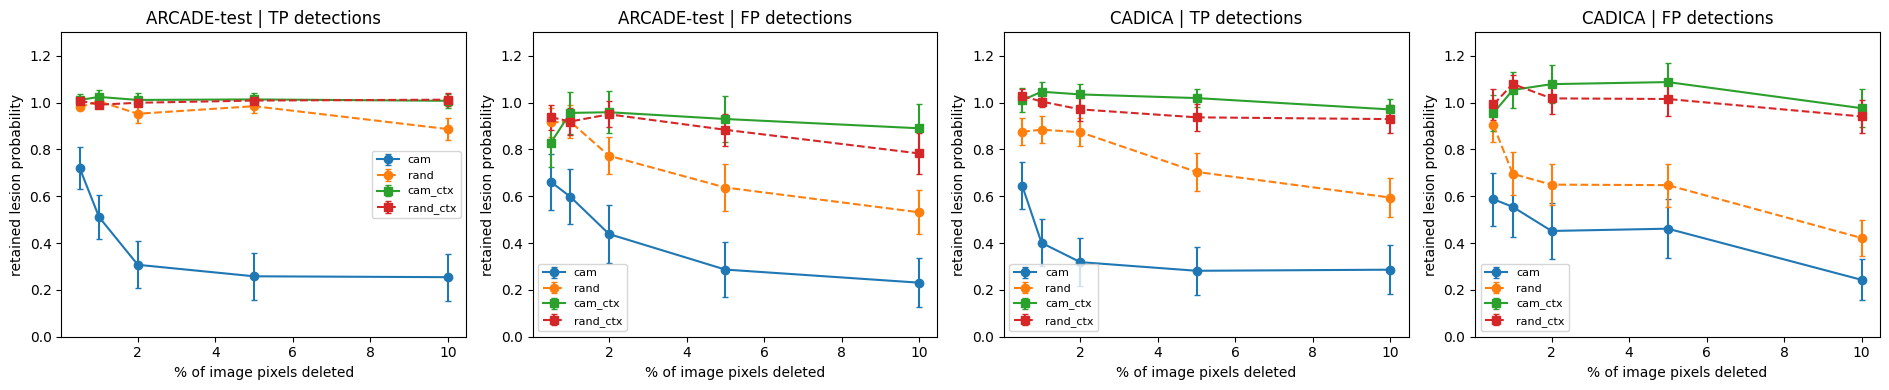

Retained probability after deleting 2% of pixels:
mode                cam  cam_ctx   rand  rand_ctx
dataset     kind                                 
ARCADE-test FP    0.438    0.959  0.773     0.950
            TP    0.307    1.011  0.952     0.999
CADICA      FP    0.452    1.079  0.650     1.018
            TP    0.318    1.035  0.874     0.971

=== SS-12: sanity check - Spearman correlation between the real CAM and the CAM after randomising weights ===
(should drop toward 0; a CAM that stays ~1.0 is NOT explaining the trained model)
    dataset  head  head+decoder   all
ARCADE-test 0.177         0.006 0.011
     CADICA 0.153        -0.006 0.038


In [20]:
def pick_rows(name, kind, n, seed=0):
    d = CAND[name]["df"]; sub = d[d.y10 == (1 if kind == "TP" else 0)]
    return sub.sample(min(n, len(sub)), random_state=seed)

# ---------- 1. localisation (TPs) ----------
def localisation(name, n=150):
    D, m, st = B_SETS[name]; inst_all = CAND[name]["inst"]; eng = SegGradCAM(m, CAM_TARGET); pg, lift, chance = [], [], []
    for r in pick_rows(name, "TP", n).itertuples():
        ins = inst_all[r.fi][r.score_rank]; g = percentile_stretch(D["imgs"][r.fi]) if st else D["imgs"][r.fi]
        gb = max(D["boxes"][r.fi], key=lambda b: box_iou(ins["box"], b))
        cam = eng.run(g, [full_mask(ins)])[0]
        x0, y0, x1, y1 = [int(round(v)) for v in gb]; x0, y0 = max(x0, 0), max(y0, 0); x1, y1 = min(x1, IMG_SIZE), min(y1, IMG_SIZE)
        if x1 <= x0 or y1 <= y0: continue
        am = np.unravel_index(np.argmax(cam), cam.shape)
        pg.append(float(y0 <= am[0] < y1 and x0 <= am[1] < x1))
        frac = (x1 - x0) * (y1 - y0) / IMG_SIZE ** 2; chance.append(frac)
        lift.append(float(cam[y0:y1, x0:x1].sum() / (cam.sum() + 1e-8)) / frac)
    eng.close()
    return dict(n=len(pg), pointing_game=np.mean(pg), chance_pointing=np.mean(chance), energy_lift=np.mean(lift))

print("=== SS-10: localisation of CAM on true lesions (TP detections) ===")
LOC = pd.DataFrame([{"dataset": k, **localisation(k)} for k in ["ARCADE-test", "CADICA"]])
print(LOC.round(3).to_string(index=False))
print("(pointing_game vs chance_pointing; energy_lift = share of CAM energy inside GT box / box area share; 1.0 = no better than uniform)")

# ---------- 2. faithfulness / deletion ----------
FRACS = [0.005, 0.01, 0.02, 0.05, 0.10]
def deletion(name, kind, n):
    D, m, st = B_SETS[name]; inst_all = CAND[name]["inst"]; eng = SegGradCAM(m, CAM_TARGET); rng = np.random.default_rng(0); out = []
    ell = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (51, 51))
    for r in pick_rows(name, kind, n).itertuples():
        ins = inst_all[r.fi][r.score_rank]; g = percentile_stretch(D["imgs"][r.fi]) if st else D["imgs"][r.fi]
        reg = full_mask(ins); cam = eng.run(g, [reg])[0]; blur = cv2.GaussianBlur(g, (0, 0), 20)
        excl = cv2.dilate(reg.astype(np.uint8), ell).astype(bool)
        base = max(float(predict_probs(m, [g], False, False)[0].astype(np.float32)[reg].mean()), 1e-6)
        variants = []
        for frac in FRACS:
            k = int(frac * IMG_SIZE ** 2)
            for mode in ["cam", "rand", "cam_ctx", "rand_ctx"]:
                smap = (cam if mode.startswith("cam") else rng.random(cam.shape)) + 1e-6 * rng.random(cam.shape)
                smap = smap.copy()
                if mode.endswith("ctx"): smap[excl] = -1
                idx = np.argpartition(-smap.ravel(), k)[:k]; M = np.zeros(IMG_SIZE * IMG_SIZE, bool); M[idx] = True
                variants.append((frac, mode, np.where(M.reshape(IMG_SIZE, IMG_SIZE), blur, g)))
        probs = predict_probs(m, [v[2] for v in variants], False, False)
        for (frac, mode, _), p in zip(variants, probs):
            out.append(dict(dataset=name, kind=kind, frac=frac, mode=mode, retained=float(np.clip(p.astype(np.float32)[reg].mean() / base, 0, 1.5))))
    eng.close(); return out

DEL = pd.DataFrame(sum([deletion(dn, k, N_EXPL // 2) for dn in ["ARCADE-test", "CADICA"] for k in ["TP", "FP"]], []))
agg = DEL.groupby(["dataset", "kind", "mode", "frac"]).retained.agg(["mean", "sem"]).reset_index()
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
for a, (dn, k) in zip(ax, [(d, k) for d in ["ARCADE-test", "CADICA"] for k in ["TP", "FP"]]):
    for mode, st_ in [("cam", "-o"), ("rand", "--o"), ("cam_ctx", "-s"), ("rand_ctx", "--s")]:
        s = agg[(agg.dataset == dn) & (agg.kind == k) & (agg["mode"] == mode)]
        a.errorbar(s.frac * 100, s["mean"], yerr=s["sem"], fmt=st_, label=mode, capsize=2)
    a.set_title(f"{dn} | {k} detections"); a.set_xlabel("% of image pixels deleted"); a.set_ylabel("retained lesion probability"); a.set_ylim(0, 1.3); a.legend(fontsize=8)
plt.tight_layout(); print("\n=== SS-11: faithfulness (deletion). Lower for 'cam' than 'rand' = faithful explanation ===")
plt.show()
piv = DEL[DEL.frac == 0.02].groupby(["dataset", "kind", "mode"]).retained.mean().unstack("mode").round(3)
print("Retained probability after deleting 2% of pixels:"); print(piv)

# ---------- 3. sanity: weight randomisation ----------
def sanity(name, n=25):
    D, m, st = B_SETS[name]; inst_all = CAND[name]["inst"]; rows_ = pick_rows(name, "TP", n)
    def rand_copy(scope):
        mc = copy.deepcopy(m)
        mods = {"head": [mc.net.segmentation_head], "head+decoder": [mc.net.segmentation_head, mc.net.decoder], "all": [mc]}[scope]
        for sub in mods:
            for mod in sub.modules():
                if hasattr(mod, "reset_parameters"): mod.reset_parameters()
        return mc
    items = []
    for r in rows_.itertuples():
        ins = inst_all[r.fi][r.score_rank]; g = percentile_stretch(D["imgs"][r.fi]) if st else D["imgs"][r.fi]; items.append((g, full_mask(ins)))
    def cams_of(mm):
        e = SegGradCAM(mm, CAM_TARGET); out = [cv2.resize(e.run(g, [reg])[0], (64, 64), interpolation=cv2.INTER_AREA).ravel() for g, reg in items]; e.close(); return out
    ref = cams_of(m); res = {}
    for scope in ["head", "head+decoder", "all"]:
        cc = cams_of(rand_copy(scope)); rho = []
        for a, b in zip(ref, cc):
            r_ = spearmanr(a, b)[0]
            rho.append(0.0 if (r_ is None or np.isnan(r_)) else r_)
        res[scope] = float(np.mean(rho))
    return res
print("\n=== SS-12: sanity check - Spearman correlation between the real CAM and the CAM after randomising weights ===")
print("(should drop toward 0; a CAM that stays ~1.0 is NOT explaining the trained model)")
SAN = pd.DataFrame([{"dataset": dn, **sanity(dn)} for dn in ["ARCADE-test", "CADICA"]])
print(SAN.round(3).to_string(index=False))

In [21]:
# ============================================================
# Save everything + auto-generated results paragraph (numbers only; interpretation is yours to check)
# ============================================================
TAB_B.to_csv(OUT_DIR / "partB_rejector_table.csv", index=False)
AUC1.to_csv(OUT_DIR / "partB_single_feature_auc.csv", index=False)
LOC.to_csv(OUT_DIR / "partB_localisation.csv", index=False)
DEL.to_csv(OUT_DIR / "partB_deletion_raw.csv", index=False)
SAN.to_csv(OUT_DIR / "partB_sanity.csv", index=False)

a, c = RES[("ARCADE-test", "zero_shot")], RES[("CADICA", "zero_shot")]
ad = RES[("CADICA", B_VARIANT)]
print("=== SS-13: auto-summary (copy these numbers into the thesis, then interpret) ===")
print(f"Zero-shot transfer: F1@IoU0.1 {a['F1_i10']:.3f} (ARCADE-test) -> {c['F1_i10']:.3f} (CADICA), "
      f"relative drop {100*(a['F1_i10']-c['F1_i10'])/max(a['F1_i10'],1e-9):.0f}%; "
      f"F1@IoU0.5 {a['F1_i50']:.3f} -> {c['F1_i50']:.3f}.")
print(f"CADICA frame-level specificity on lesion-free frames (zero-shot): {c['frame_spec']:.3f}; "
      f"with {B_VARIANT}: {ad['frame_spec']:.3f}.")
print(f"Best CADICA F1@IoU0.1 among variants: " + ", ".join(f"{v}={RES[('CADICA', v)]['F1_i10']:.3f}" for v in VARIANTS))
print("Rejector (CADICA): " + "; ".join(f"{r['method']}: F1@.1 {r['F1@.1 [95% CI]']}" for _, r in TAB_B[TAB_B.dataset == 'CADICA'].iterrows()))
print("\nSaved all tables to", OUT_DIR)
shutil.make_archive("/content/results_cadica_crossdataset", "zip", OUT_DIR)
try:
    from google.colab import files; files.download("/content/results_cadica_crossdataset.zip")
except Exception as e:
    print("Download the zip manually from /content/results_cadica_crossdataset.zip", repr(e)[:80])

=== SS-13: auto-summary (copy these numbers into the thesis, then interpret) ===
Zero-shot transfer: F1@IoU0.1 0.703 (ARCADE-test) -> 0.419 (CADICA), relative drop 40%; F1@IoU0.5 0.281 -> 0.113.
CADICA frame-level specificity on lesion-free frames (zero-shot): 0.146; with adabn: 0.141.
Best CADICA F1@IoU0.1 among variants: zero_shot=0.419, stretch=0.445, adabn=0.422, adabn+stretch=0.428
Rejector (CADICA): baseline (score cut): F1@.1 0.427 [0.383,0.478]; rejector: basic: F1@.1 0.418 [0.369,0.474]; rejector: basic+context: F1@.1 0.420 [0.371,0.475]; rejector: CAM only (+score): F1@.1 0.408 [0.365,0.459]; rejector: basic+context+CAM: F1@.1 0.419 [0.372,0.473]

Saved all tables to /content/outputs


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How to read the results (so you do not over-claim)
* **Part A.** The drop is a *measured* number, with a patient-level CI. If AdaBN/stretch recovers part of it, say exactly that, and say it did so **without any CADICA labels**. If it does not help, that is also a valid, reportable result.
* **Severity table (SS-5).** If recall is low for `<50 %` lesions but fine for `>=70 %`, the "drop" is partly a *label-definition shift* (ARCADE does not cover mild lesions the same way), not only image-domain shift. That is an insight, not a failure.
* **Part B.** Three claims are supportable *only if the numbers say so*:
  1. localisation: pointing game and energy lift clearly above chance;
  2. faithfulness: `cam` deletion drops the retained probability more than `rand`;
  3. sanity: correlation falls toward 0 after randomisation.
* **Rejector.** The question is whether `basic+context+CAM` beats `basic+context` (look at the ΔAUC and its CI in SS-9). If the CI includes 0, CAM features did **not** add value; report that honestly and keep the finding about *why* false positives occur.
* **Never compare these box-level F1 values to StenUNet's 0.535** (different protocol, different dataset).